In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import ScalarFormatter
%matplotlib inline
import pandas as pd
from planet_cookbook import read_reports as rr
import os
import rebound
import seaborn as sns

sol_to_earth = 332946.078
G = 6.6743* 10**(-11) #N⋅m2/kg2
M_sun = 1.989e+33 #g
AU = 1.496e+13 #cm

params = {
   'axes.labelsize': 15,
   'font.size': 15,
   'legend.fontsize': 10,
   'xtick.labelsize': 15,
   'ytick.labelsize': 15,
   'text.usetex': True, #to use TeX in your labels
   'font.family':'serif',
   'axes.titlesize': 15
   }
rcParams.update(params)

In [20]:
n_runs = 50

ueda_dfs = []
cham_bi_tajer_dfs = []
cham_cont_dfs = []

for i in range(1,n_runs+1):
    path =  f"/Users/honeyeah/Codes/data/ueda_v5/ueda_v5_{i}/collision_report.txt"
    df_temp = pd.read_csv(path, sep=r"\s+", header=None,
                          names=["time", "type", "b", "hash_t", "m_t", "r_t", "hash_p", "r_p"] + [f"col{i}" for i in range(9, 100)])
    df_temp["sim_id"] = i
    ueda_dfs.append(df_temp)

ueda_all = pd.concat(ueda_dfs, ignore_index=True)

for i in range(1,n_runs+1):
    path =  f"/Users/honeyeah/Codes/data/cham_bi_tajer/cham_bi_tajer_{i}/collision_report.txt"
    df_temp = pd.read_csv(path, sep=r"\s+", header=None,
                          names=["time", "type", "b", "hash_t", "m_t", "r_t", "hash_p", "r_p"] + [f"col{i}" for i in range(9, 100)])
    df_temp["sim_id"] = i
    cham_bi_tajer_dfs.append(df_temp)

cham_bi_tajer_all = pd.concat(cham_bi_tajer_dfs, ignore_index=True)

for i in range(1,n_runs+1):
    path =  f"/Users/honeyeah/Codes/data/cham_cont/cham_cont_{i}/collision_report.txt"
    df_temp = pd.read_csv(path, sep=r"\s+", header=None,
                          names=["time", "type", "b", "hash_t", "m_t", "r_t", "hash_p", "r_p"] + [f"col{i}" for i in range(9, 105)])
    df_temp["sim_id"] = i
    cham_cont_dfs.append(df_temp)

cham_cont_all = pd.concat(cham_cont_dfs, ignore_index=True)

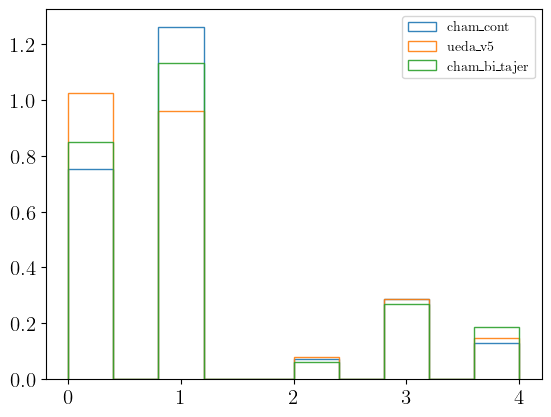

In [30]:
plt.hist(cham_cont_all['type'], label = 'cham_cont', density='True', alpha = 0.9, histtype='step')
plt.hist(ueda_all['type'], label = 'ueda_v5', density='True', alpha = 0.9, histtype='step')
plt.hist(cham_bi_tajer_all['type'], label = 'cham_bi_tajer', density='True', alpha = 0.9, histtype='step')


plt.legend()
plt.show()

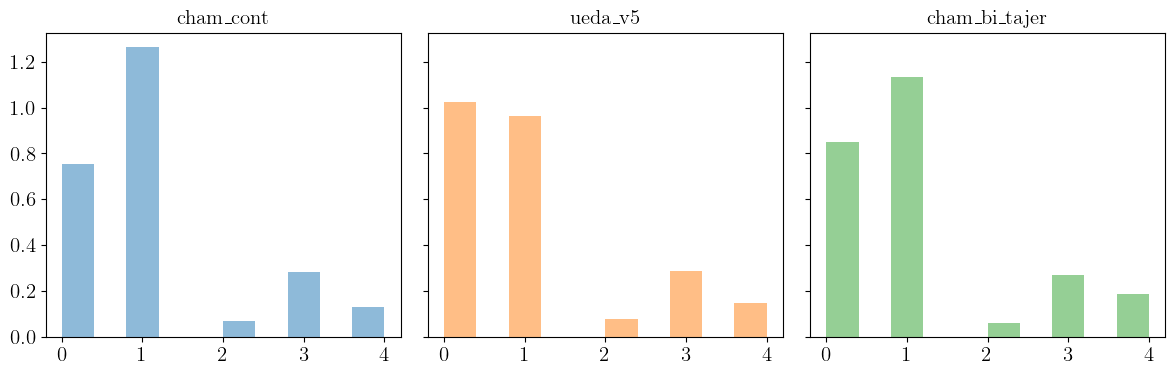

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)

axes[0].hist(cham_cont_all['type'], density=True, alpha=0.5, color="C0")
axes[0].set_title("cham_cont")

axes[1].hist(ueda_all['type'], density=True, alpha=0.5, color="C1")
axes[1].set_title("ueda_v5")

axes[2].hist(cham_bi_tajer_all['type'], density=True, alpha=0.5, color="C2")
axes[2].set_title("cham_bi_tajer")

plt.tight_layout()
plt.show()


In [57]:
ueda_fragments = ueda_all[ueda_all['hash_t'] > 200]
ueda_closer_ones = ueda_all[ueda_all['hash_t'] < 50]
ueda_further_ones = ueda_all[(ueda_all['hash_t'] > 100) & (ueda_all['hash_t'] < 151)]

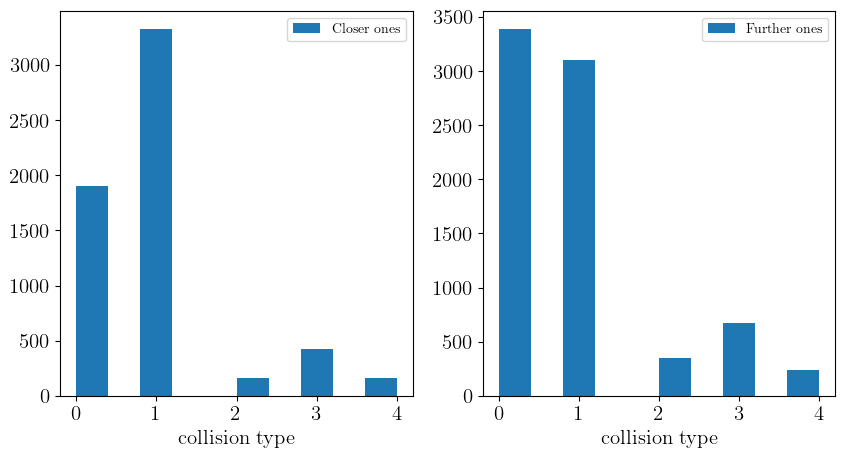

In [58]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.hist(ueda_closer_ones['type'], label = 'Closer ones')
plt.xlabel("collision type")
plt.legend()

plt.subplot(1,2,2)
plt.hist(ueda_further_ones['type'], label = 'Further ones')
plt.xlabel("collision type")
plt.legend()
plt.show()

In [60]:
ueda_all

,time,type,b,hash_t,m_t,r_t,hash_p,r_p,col9,col10,...,col91,col92,col93,col94,col95,col96,col97,col98,col99,sim_id
0,1.372108e+02,1,0.000023,71,8.810000e-08,0.000016,67,0.000013,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,5.206626e+02,1,0.000022,77,8.810000e-08,0.000016,40,0.000013,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2,7.031332e+02,1,0.000008,118,8.810000e-08,0.000016,109,0.000013,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
3,2.183071e+03,1,0.000014,94,8.810000e-08,0.000016,80,0.000013,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
4,2.557675e+03,1,0.000011,97,8.810000e-08,0.000016,73,0.000013,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25330,4.609503e+07,3,0.000010,4055959668,4.458614e-08,0.000009,1405660995,0.000007,3.662110e+09,2.826744e-08,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50
25331,4.610450e+07,0,0.000016,4055959668,4.458614e-08,0.000009,3662110242,0.000008,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50
25332,4.746708e+07,4,0.000006,4055959668,2.202500e-08,0.000007,1820499179,0.000008,2.247027e+09,2.333656e-08,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50
25333,4.750628e+07,0,0.000012,2247026945,2.333656e-08,0.000008,4055959668,0.000007,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50


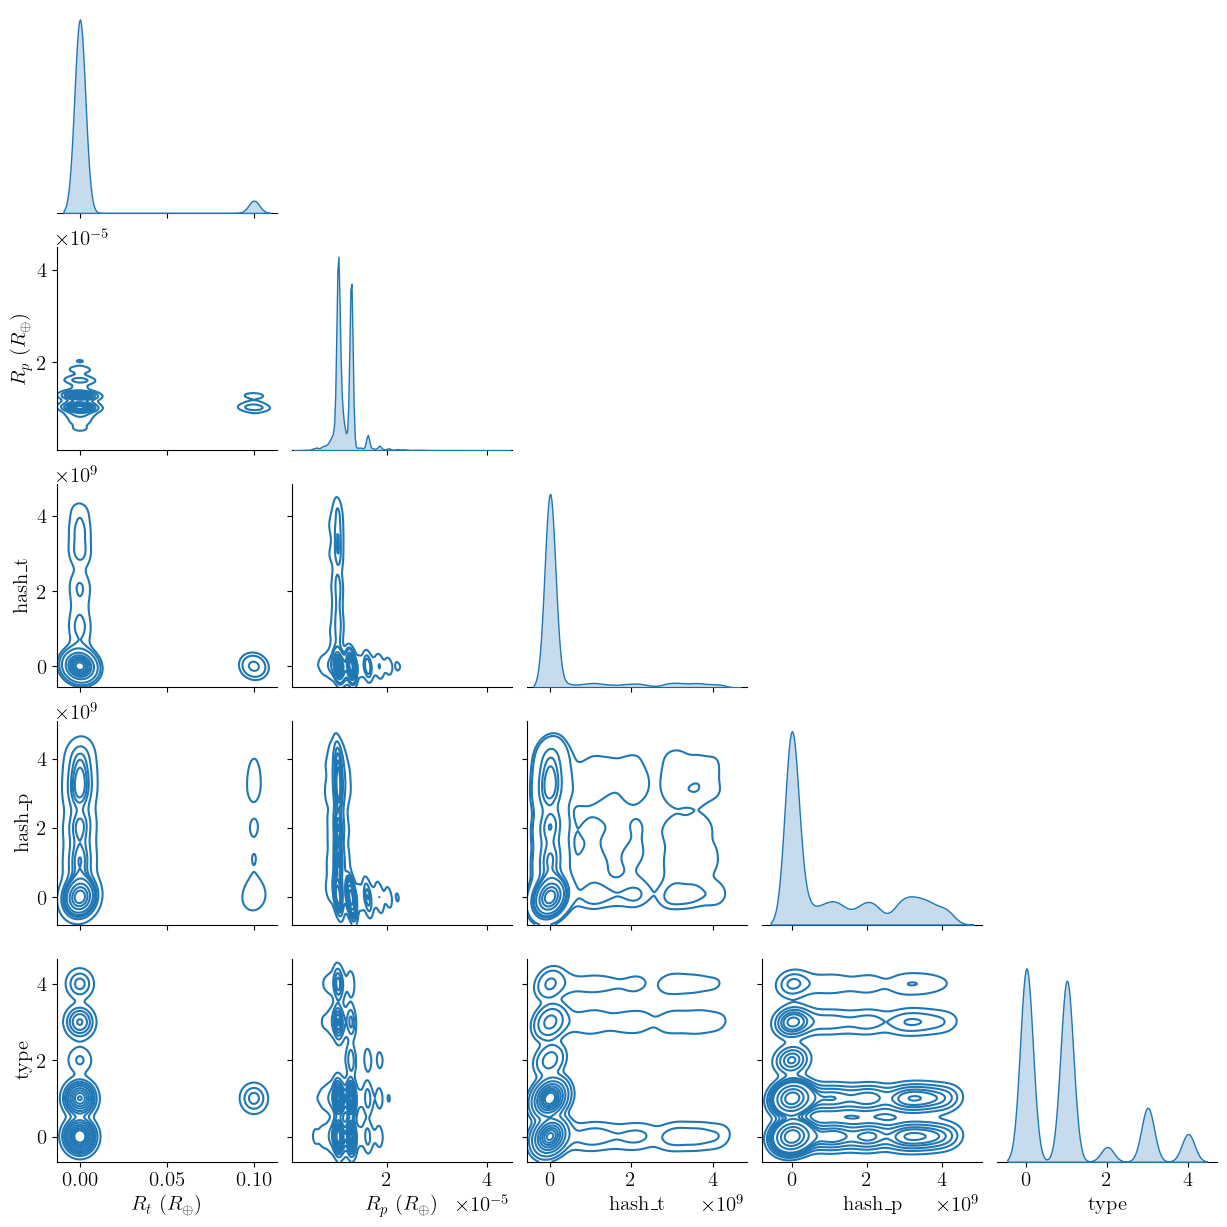

In [ ]:
# Select the columns for the corner plot
#corner_cols = ['r_t', 'r_p', 'hash_t', 'hash_p', 'type']
corner_cols = ['r_t', 'r_p', 'type']
custom_labels = [r"$R_{t}$ ($R_{\oplus}$)", r"$R_{p}$ ($R_{\oplus}$)", 'hash_t', 'hash_p', 'type']


# Drop rows with NaN in these columns to avoid plotting issues
plot_df = ueda_all[corner_cols].dropna()

# After your pairplot code
g = sns.pairplot(
    plot_df,
    corner=True,
    kind='kde',
    diag_kind="kde",
)
# Overlay vertical/horizontal lines for ranges
axes = g.axes

#axes[0,0].axvspan(Mt_range[0], Mt_range[1], color='orange', alpha=0.2, label='Mt_range')
#axes[2,2].axvspan(Vi_range[0], Vi_range[1], color='green', alpha=0.2, label='Vi_range')  # single value
#axes[3,3].axvspan(theta_range[0], theta_range[1], color='purple', alpha=0.2, label='theta_range')
# Set axis labels
for i, label in enumerate(custom_labels):
    g.axes[i,0].set_ylabel(label)
    g.axes[-1,i].set_xlabel(label)

# Optionally add legends
#for i, ax in enumerate(np.diag(axes)):
#    ax.legend()
#plt.savefig('cornerplot.pdf', dpi=300)
plt.show()